# Pal et al. 2021 - Breast Cancer . 04 EMT-TF Expression
Unconditional final step (renumbered 04: Gate 2 GO non-branching -> no branching-only 04_correlation / 05_modules). Score a broadened EMT-TF panel gated on detectable expression; overlay the two most pseudotime-informative TFs as a **categorical thresholded-expresser overlay on grey** (house style), not a continuous colormap.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load signatures; use the Body linear layout

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('body cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

body cells: 44398 | pseudotime range 0.0 -> 8.68


### EMT-TF panel, detection-gated; derive the informative pair

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,p=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df=pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['peak']=np.where(df.mean_early>df.mean_late,'origin','terminus')
df=df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok=df[df.frac_expr>0.03]
print('expressed (frac>0.03):', list(ok.TF))
# All detected EMT-TFs peak toward the origin (rho<0, mean_early>mean_late): EMT-TF activity is origin-weighted;
# none is Crest-terminal. Show the most origin-concentrated factor vs the one that extends latest along pseudotime.
origin_tf=ok.sort_values('rho_vs_t').iloc[0]['TF']       # most origin-enriched (most negative rho)
latest_tf=ok.sort_values('rho_vs_t').iloc[-1]['TF']      # least origin-enriched (extends latest)
n_terminal=int((ok.peak=='terminus').sum())
print(f'EMT-TF activity is origin-weighted: {int((ok.peak=="origin").sum())}/{len(ok)} expressed TFs peak at the origin, '
      f'{n_terminal} at the terminus -> no Crest-terminal EMT-TF.')
print(f'derived pair: {origin_tf} (origin-peak) <-> {latest_tf} (extends latest, sub-terminal)')
early_tf, late_tf = origin_tf, latest_tf

    TF  frac_expr  mean_early  mean_late  rho_vs_t     peak
 PRRX2      0.061       0.077      0.007    -0.230   origin
 FOXC2      0.033       0.057      0.002    -0.227   origin
 SNAI2      0.061       0.066      0.011    -0.160   origin
 PRRX1      0.019       0.028      0.002    -0.145   origin
 FOXC1      0.138       0.095      0.049    -0.095   origin
 SNAI1      0.044       0.012      0.007    -0.030   origin
  ZEB2      0.012       0.004      0.002    -0.018   origin
  ZEB1      0.006       0.003      0.001    -0.016   origin
TWIST2      0.003       0.001      0.001    -0.012 terminus
TWIST1      0.024       0.004      0.008     0.048 terminus
expressed (frac>0.03): ['PRRX2', 'FOXC2', 'SNAI2', 'FOXC1', 'SNAI1']
EMT-TF activity is origin-weighted: 5/5 expressed TFs peak at the origin, 0 at the terminus -> no Crest-terminal EMT-TF.
derived pair: PRRX2 (origin-peak) <-> SNAI1 (extends latest, sub-terminal)


### expression.pdf - categorical thresholded-expresser overlay on grey

overlay thresholds (upper quartile among expressers): {'PRRX2': 0.691, 'SNAI1': 0.303} | cells shown: {'PRRX2': 673, 'SNAI1': 489}
PRRX2: 6.1% expressing; 673 shown (upper quartile), mean pseudotime of shown cells = 0.09 (all = 0.55)
SNAI1: 4.4% expressing; 489 shown (upper quartile), mean pseudotime of shown cells = 0.50 (all = 0.55)
saved expression.pdf


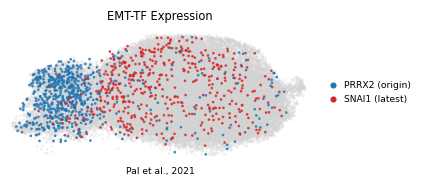

In [5]:
xl=adata.obsm['X_umap']; xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [early_tf,late_tf]})
order=sorted([early_tf,late_tf], key=lambda g:-int(sel[g].sum()))
colors={early_tf:'tab:blue', late_tf:'tab:red'}
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=12, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap=adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=12, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=early_tf+' (origin)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=late_tf+' (latest)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m=sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')